# Simulated person: linear observer in a 2IFC RC task

Implements the model in [model/01-simulated-person-on-paper.md](../model/01-simulated-person-on-paper.md), one function at a time.

| Equation | Function | Status |
|---|---|---|
| θ random, length 1 | `make_template(d)` | ✅ this notebook |
| n ~ N(0, I) | `make_noise(n_trials, d)` | ✅ this notebook |
| choose the top k of n noisy scores (2IFC: base + n if θᵀn + ε > 0) | `observer_choose(images, theta, sigma, k)`, `choices_to_sign(chosen)` | ✅ this notebook |
| CI = Σ s·n | `classification_image(noise, s)` | to do |
| cos(CI, θ) | `cosine(a, b)` | to do |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEED = 2026
rng = np.random.default_rng(SEED)

In [2]:
def _check_positive_int(name, value):
    """Raise ValueError unless value is a positive integer (rejects bool, float and None)."""
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{name} must be a positive integer, got {value!r}")

## 1. `make_template(d)` → θ

The hidden template θ is a **random unit vector** in d dimensions:

1. draw g ~ N(0, I_d);
2. set θ = g / ‖g‖.

Because N(0, I) is spherically symmetric, θ is **uniform over the unit sphere**: no direction is favoured.

In [3]:
def make_template(d, rng=None):
    """Return a random unit vector θ of shape (d,), uniform over the sphere in R^d.

    Parameters
    ----------
    d : int
        Number of dimensions of the stimulus space (d >= 1).
    rng : None, int or np.random.Generator, optional
        Seed or generator, for reproducible runs (passed to np.random.default_rng).
    """
    _check_positive_int("d", d)
    rng = np.random.default_rng(rng)
    g = rng.standard_normal(d)
    return g / np.linalg.norm(g)

## 2. Checks

In [4]:
d = 10
theta = make_template(d, rng)
print("theta =", np.round(theta, 3))
print("shape =", theta.shape, "| norm =", np.linalg.norm(theta))

# Unit length
assert theta.shape == (d,)
assert np.isclose(np.linalg.norm(theta), 1.0)

# Reproducible: same seed -> same template
a = make_template(d, np.random.default_rng(1))
b = make_template(d, np.random.default_rng(1))
assert np.array_equal(a, b)
assert np.array_equal(a, make_template(d, 1))   # an int seed works too

# Bad input is rejected
for bad in (0, -3, 2.5, True, None):
    try:
        make_template(bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"make_template({bad}) should fail")
print("All checks passed.")

theta = [-0.299  0.091 -0.715  0.526  0.241 -0.11  -0.118  0.115 -0.101 -0.085]
shape = (10,) | norm = 1.0
All checks passed.


### Is θ really uniform on the sphere?

Draw many templates. If θ is uniform:

- every coordinate has mean ≈ 0 and variance ≈ 1/d;
- the cosine between two independent templates (a pure "random guess" in §4 of the model) has **mean ≈ 0**, mean |cos| ≈ 0.26 and **RMS ≈ 1/√d ≈ 0.32** for d = 10.

max |mean of a coordinate| : 0.0035
variance per coordinate    : [0.1015 0.1    0.1007 0.1005 0.0988 0.1001 0.0991 0.0985 0.1011 0.0996] (expected 0.1000)

random-guess cosine: mean = 0.000, mean |cos| = 0.258, RMS = 0.314 (1/sqrt(d) = 0.316)


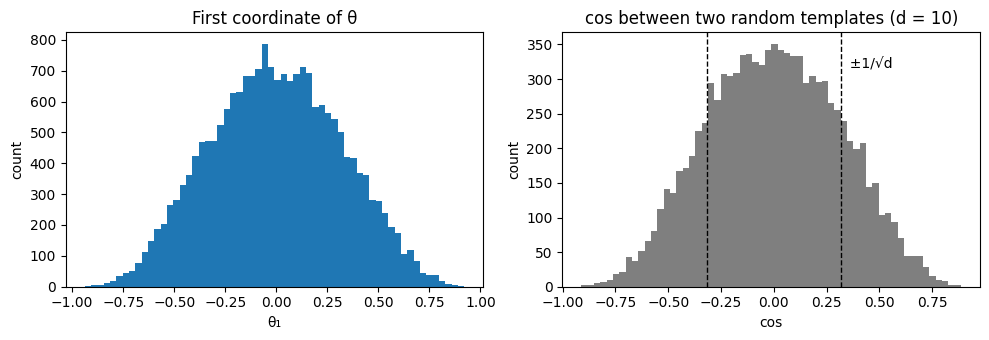

In [5]:
n_templates = 20_000
thetas = np.stack([make_template(d, rng) for _ in range(n_templates)])

print("max |mean of a coordinate| :", np.abs(thetas.mean(axis=0)).max().round(4))
print("variance per coordinate    :", thetas.var(axis=0).round(4), f"(expected {1/d:.4f})")

# Cosine between pairs of independent templates (all unit length, so cos = dot product)
cos_random = np.sum(thetas[0::2] * thetas[1::2], axis=1)
print(f"\nrandom-guess cosine: mean = {cos_random.mean():.3f}, "
      f"mean |cos| = {np.abs(cos_random).mean():.3f}, "
      f"RMS = {np.sqrt(np.mean(cos_random**2)):.3f} (1/sqrt(d) = {1/np.sqrt(d):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(thetas[:, 0], bins=60, color="tab:blue")
axes[0].set(title="First coordinate of θ", xlabel="θ₁", ylabel="count")
axes[1].hist(cos_random, bins=60, color="tab:gray")
for x in (-1/np.sqrt(d), 1/np.sqrt(d)):
    axes[1].axvline(x, ls="--", color="k", lw=1)
axes[1].set(title=f"cos between two random templates (d = {d})", xlabel="cos", ylabel="count")
axes[1].text(1/np.sqrt(d), axes[1].get_ylim()[1]*0.9, "  ±1/√d", va="top")
plt.tight_layout()
plt.show()

## 3. `make_noise(n_trials, d)` → noise vectors

One noise pattern per trial, each drawn independently: **n_t ~ N(0, I_d)**.

Returned as an array of shape **(n_trials, d)**: row t is n_t. On trial t the two images are *base + n_t* and *base − n_t*.

Because ‖θ‖ = 1 and N(0, I) is spherically symmetric, the projection **θᵀn_t ~ N(0, 1)** whatever θ is. That is why σ in the model is directly the internal-to-stimulus noise ratio.

In [6]:
def make_noise(n_trials, d, rng=None):
    """Return noise patterns of shape (n_trials, d); row t is n_t ~ N(0, I_d), independent across trials.

    Parameters
    ----------
    n_trials : int
        Number of trials N (>= 1).
    d : int
        Number of dimensions of the stimulus space (>= 1).
    rng : None, int or np.random.Generator, optional
        Seed or generator, for reproducible runs (passed to np.random.default_rng).
    """
    _check_positive_int("n_trials", n_trials)
    _check_positive_int("d", d)
    rng = np.random.default_rng(rng)
    return rng.standard_normal((n_trials, d))

### Checks

In [7]:
n_trials = 300
noise = make_noise(n_trials, d, rng)
print("shape =", noise.shape)
assert noise.shape == (n_trials, d)

# Reproducible: same seed -> same noise
assert np.array_equal(make_noise(5, d, np.random.default_rng(1)),
                      make_noise(5, d, np.random.default_rng(1)))

# Bad input is rejected
for bad in ((0, d), (n_trials, 0), (2.5, d), (n_trials, -1), (True, d), (n_trials, None)):
    try:
        make_noise(*bad)
    except ValueError:
        pass
    else:
        raise AssertionError(f"make_noise{bad} should fail")

# Distribution: mean 0 and covariance I, over many trials
big = make_noise(200_000, d, rng)
cov = np.cov(big, rowvar=False)
print("max |mean|               :", np.abs(big.mean(axis=0)).max().round(4))
print("max |cov - I|            :", np.abs(cov - np.eye(d)).max().round(4))

# Projection on a unit template is N(0, 1).
# errstate: NumPy 2.0 + macOS system BLAS can emit false divide/overflow warnings from `@`;
# the assert below checks that the result itself is fine.
with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
    proj = big @ theta
assert np.isfinite(proj).all()
print(f"theta^T n: mean = {proj.mean():.3f}, SD = {proj.std():.3f} (expected 0 and 1)")
print("All checks passed.")

shape = (300, 10)
max |mean|               : 0.0041
max |cov - I|            : 0.0059
theta^T n: mean = -0.001, SD = 0.999 (expected 0 and 1)
All checks passed.


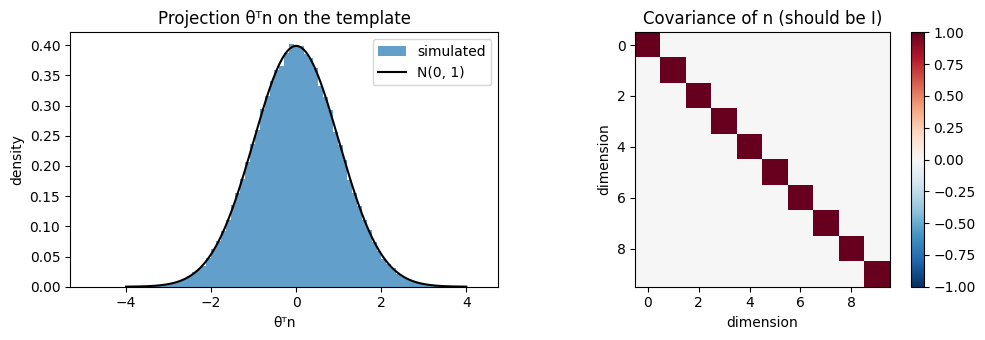

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))

x = np.linspace(-4, 4, 200)
axes[0].hist(proj, bins=80, density=True, color="tab:blue", alpha=0.7, label="simulated")
axes[0].plot(x, np.exp(-x**2 / 2) / np.sqrt(2 * np.pi), "k", lw=1.5, label="N(0, 1)")
axes[0].set(title="Projection θᵀn on the template", xlabel="θᵀn", ylabel="density")
axes[0].legend()

im = axes[1].imshow(cov, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set(title="Covariance of n (should be I)", xlabel="dimension", ylabel="dimension")
fig.colorbar(im, ax=axes[1], fraction=0.046)

plt.tight_layout()
plt.show()

## 4. `observer_choose(images, theta, sigma, k=1)` → which images were chosen

**General rule (k of n).** On each trial the simulated person sees n images x₁ … xₙ and gives each one an internal score

$$u_i = \theta^\top x_i + \eta_i, \qquad \eta_i \sim N(0,\ \sigma^2)\ \text{independent across images and trials},$$

then picks the **k images with the highest scores**. So **`sigma` is the SD of the noise on each image's score** (per-image σ).

**Link to the 2IFC rule in the model.** With n = 2, k = 1 and images b + n, b − n:

$$u_1 > u_2 \iff 2\theta^\top n + (\eta_1 - \eta_2) > 0 \iff \theta^\top n + \varepsilon > 0, \quad \varepsilon = \tfrac{\eta_1 - \eta_2}{2} \sim N\!\left(0, \tfrac{\sigma^2}{2}\right).$$

So the model's 2IFC noise is **σ_model = σ / √2**, and P(pick b + n) = Φ(√2 · θᵀn / σ). When comparing with the predictions in §6 of the [model](../model/01-simulated-person-on-paper.md), use σ_model = `sigma` / √2.

**Other properties**
- The base b is shared by all images, so it adds the same θᵀb to every score and **never changes the choice** (linear observer).
- σ = 0: the person always picks the true top k by θᵀx.
- σ → ∞: choices become random, each image chosen with probability k/n.

**Shapes.** `images` is `(n, d)` for one trial or `(..., n, d)` for many (e.g. `(n_trials, n, d)`). The result is a boolean array `(..., n)` with exactly k `True` per trial.

**2IFC convention.** Images are always stacked as **`[base + n, base − n]`**, so column 0 is +n and column 1 is −n. `choices_to_sign` turns the boolean result into s_t = ±1 for `classification_image`.

In [9]:
def observer_choose(images, theta, sigma, k=1, rng=None):
    """Simulated linear observer: pick the k of n images with the highest noisy score.

    Score of image i on a trial: u_i = theta^T x_i + eta_i, eta_i ~ N(0, sigma^2), independent.

    Parameters
    ----------
    images : array, shape (n, d) or (..., n, d)
        The n images shown on each trial (leading axes = trials).
    theta : array, shape (d,)
        Hidden template.
    sigma : float >= 0
        SD of the internal noise on EACH image's score (per-image sigma), for any n and k.
        For a 2IFC pair (b + n, b - n) this equals the model's rule theta^T n + eps > 0
        with eps ~ N(0, sigma^2 / 2), i.e. sigma_model = sigma / sqrt(2).
    k : int, 1 <= k < n
        Number of images chosen per trial.
    rng : None, int or np.random.Generator, optional
        Seed or generator, for reproducible runs (passed to np.random.default_rng).

    Returns
    -------
    chosen : bool array, shape images.shape[:-1]; exactly k True per trial.
    """
    images = np.asarray(images, dtype=float)
    theta = np.asarray(theta, dtype=float)
    if images.ndim < 2:
        raise ValueError(f"images must have shape (..., n, d), got {images.shape}")
    n, d = images.shape[-2:]
    if theta.shape != (d,):
        raise ValueError(f"theta must have shape ({d},), got {theta.shape}")
    if isinstance(sigma, bool) or not sigma >= 0:
        raise ValueError(f"sigma must be >= 0, got {sigma!r}")
    _check_positive_int("k", k)
    if k >= n:
        raise ValueError(f"k must be < n = {n}, got {k!r}")
    rng = np.random.default_rng(rng)

    # einsum instead of `@`: avoids the false floating-point warnings that matmul gives with
    # Apple's Accelerate BLAS in some NumPy versions (section 3). After upgrading NumPy,
    # check whether `@` still warns.
    scores = np.einsum("...nd,d->...n", images, theta)
    scores = scores + sigma * rng.standard_normal(scores.shape)

    # argsort sorts all n scores; fine for n = 2 or ~10 images (argpartition would be faster for big n).
    top_k = np.argsort(-scores, axis=-1)[..., :k]
    chosen = np.zeros(scores.shape, dtype=bool)
    np.put_along_axis(chosen, top_k, True, axis=-1)
    return chosen


def choices_to_sign(chosen):
    """2IFC responses as s_t = +1 / -1.

    chosen : bool array, shape (N, 2), from observer_choose on images stacked as
             [base + n, base - n]  (column 0 = +n, column 1 = -n).
    """
    chosen = np.asarray(chosen, dtype=bool)
    if chosen.ndim != 2 or chosen.shape[1] != 2 or not (chosen.sum(axis=1) == 1).all():
        raise ValueError("chosen must have shape (N, 2) with exactly one True per row")
    return np.where(chosen[:, 0], 1, -1)

### Checks

In [10]:
from math import erf, sqrt
Phi = lambda z: 0.5 * (1 + erf(z / sqrt(2)))      # standard normal CDF

base = np.zeros(d)                                  # any base works for a linear observer
noise = make_noise(n_trials, d, rng)
images_2ifc = np.stack([base + noise, base - noise], axis=1)   # (n_trials, 2, d): column 0 = +n

# Shape, exactly one chosen per trial, and the +/-1 conversion
chosen = observer_choose(images_2ifc, theta, sigma=1.0, rng=rng)
assert chosen.shape == (n_trials, 2) and (chosen.sum(axis=1) == 1).all()
s = choices_to_sign(chosen)
assert set(np.unique(s)) <= {-1, 1} and np.array_equal(s == 1, chosen[:, 0])
print("first 10 responses s_t:", s[:10])

# sigma = 0: always the image with the larger theta^T x
proj_t = np.einsum("td,d->t", noise, theta)
assert np.array_equal(choices_to_sign(observer_choose(images_2ifc, theta, 0.0)), np.sign(proj_t))

# Per-image sigma: P(pick base + n) = Phi(sqrt(2) * theta^T n / sigma)
n_fixed = 0.5 * theta                               # a noise pattern with theta^T n = 0.5
reps, sigma = 100_000, 1.0
pair = np.broadcast_to(np.stack([n_fixed, -n_fixed]), (reps, 2, d))
p_hat = observer_choose(pair, theta, sigma, rng=rng)[:, 0].mean()
p_model = Phi(sqrt(2) * 0.5 / sigma)
print(f"P(pick base + n) with theta^T n = 0.5, sigma = 1: simulated {p_hat:.3f}, "
      f"Phi(sqrt(2) * 0.5) = {p_model:.3f}")
assert abs(p_hat - p_model) < 0.01

# Seeds: an int seed is reproducible
assert np.array_equal(observer_choose(images_2ifc, theta, 1.0, rng=42),
                      observer_choose(images_2ifc, theta, 1.0, rng=42))

# The base never changes the choice (same random numbers, shifted base)
shifted = images_2ifc + 5 * make_template(d, rng)
assert np.array_equal(observer_choose(images_2ifc, theta, 1.0, rng=7),
                      observer_choose(shifted,     theta, 1.0, rng=7))

# k of n, sigma = 0: picks exactly the true top k
n_img, k = 6, 2
imgs = make_noise(n_trials * n_img, d, rng).reshape(n_trials, n_img, d)
true_top = np.argsort(-np.einsum("tnd,d->tn", imgs, theta), axis=1)[:, :k]
picked = observer_choose(imgs, theta, 0.0, k=k)
assert (picked.sum(axis=1) == k).all()
assert all(set(np.flatnonzero(picked[t])) == set(true_top[t]) for t in range(n_trials))

# k of n, huge sigma: random, each image chosen with probability k/n
freq = observer_choose(np.broadcast_to(imgs[0], (reps, n_img, d)), theta, 1e6, k=k, rng=rng).mean(axis=0)
print(f"choice rates with sigma = 1e6 (expected k/n = {k/n_img:.3f}):", freq.round(3))
assert np.allclose(freq, k / n_img, atol=0.01)

# Bad input is rejected
for kwargs in ({"k": 0}, {"k": 2}, {"k": 1.5}, {"k": True}, {"sigma": -1}):
    args = dict(images=images_2ifc, theta=theta, sigma=1.0) | kwargs
    try:
        observer_choose(**args)
    except ValueError:
        pass
    else:
        raise AssertionError(f"observer_choose with {kwargs} should fail")
try:
    choices_to_sign(picked)                         # shape (N, 6) is not 2IFC
except ValueError:
    pass
else:
    raise AssertionError("choices_to_sign should reject non-2IFC input")
print("All checks passed.")

first 10 responses s_t: [-1 -1  1 -1 -1  1  1 -1  1 -1]
P(pick base + n) with theta^T n = 0.5, sigma = 1: simulated 0.761, Phi(sqrt(2) * 0.5) = 0.760
choice rates with sigma = 1e6 (expected k/n = 0.333): [0.333 0.335 0.334 0.331 0.334 0.332]
All checks passed.


### How choice depends on θᵀn and σ (2IFC)

Each curve is the simulated probability of picking *base + n* against θᵀn, compared with Φ(√2 · θᵀn / σ) for per-image σ. Larger σ flattens the curve: the same noise pattern gives a less reliable response.

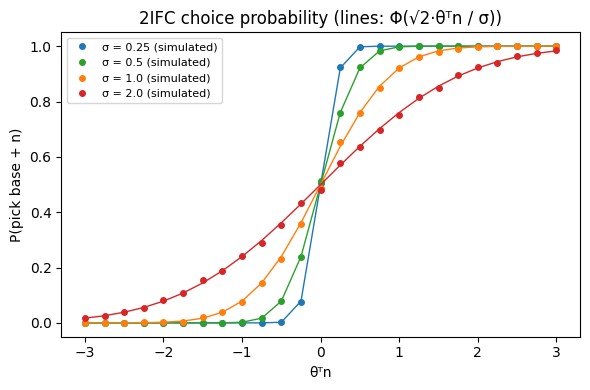

In [11]:
xs = np.linspace(-3, 3, 25)
reps = 4_000
fig, ax = plt.subplots(figsize=(6, 4))
for sig, color in zip((0.25, 0.5, 1.0, 2.0), ("tab:blue", "tab:green", "tab:orange", "tab:red")):
    p_sim = []
    for x in xs:
        pair = np.broadcast_to(np.stack([x * theta, -x * theta]), (reps, 2, d))
        p_sim.append(observer_choose(pair, theta, sig, rng=rng)[:, 0].mean())
    ax.plot(xs, p_sim, "o", ms=4, color=color, label=f"σ = {sig} (simulated)")
    ax.plot(xs, [Phi(sqrt(2) * x / sig) for x in xs], "-", color=color, lw=1)
ax.set(xlabel="θᵀn", ylabel="P(pick base + n)", title="2IFC choice probability (lines: Φ(√2·θᵀn / σ))")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()